In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.9/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.9/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
from pyCRLD.Environments.TwoArmedBandit import TwoArmedBandit
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Agents.StrategySARSA import stratSARSA
from pyCRLD.Utils.Trajectories1D import trajectories_1D 
import numpy as np

In [ ]:
env = TwoArmedBandit(rew=1, pun=-1, pA=0.3, pB=0.1)

In [ ]:
mae = stratSARSA(env=env, learning_rates=0.05, discount_factors=0.9, choice_intensities=4., use_prefactor=False)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [ ]:
x = ([0], [0, 1, 2], [0])
res = np.linspace(0, 1., 11)

KeyboardInterrupt: 

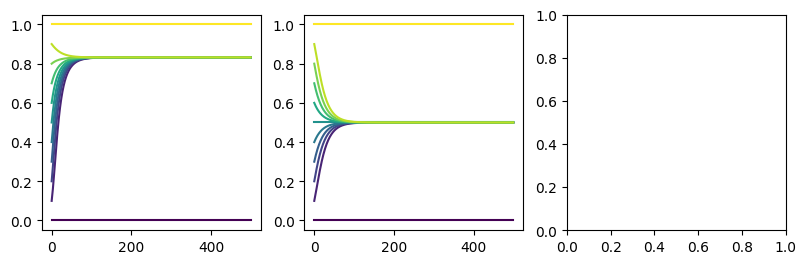

In [ ]:
trajectories_1D(mae, x, res, NrRandom=4)

In [ ]:
from qDDRLBase import qbase
from qBaseAC import qbaseAC
from qBaseSARSA import qbaseSARSA

In [ ]:
qbAC = qbaseAC(env, nr_reward_bins=29, discretization_sigma=0.1, learning_rates=0.4, discount_factors=0.9, quantile=None)

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

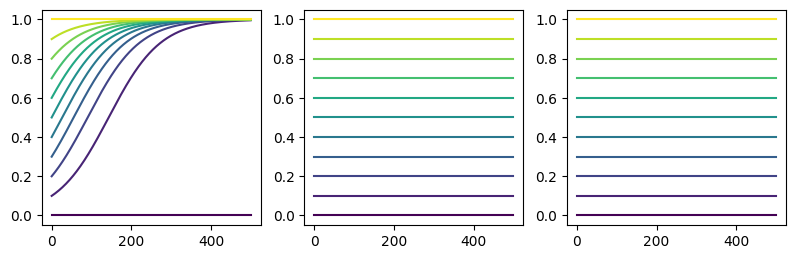

In [ ]:
trajectories_1D(qbAC, x, res, NrRandom=1)

In [ ]:
qbSARSA = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, learning_rates=0.05, discount_factors=0.9, choice_intensities=4, quantile=0.8, use_prefactor=False)

array([<Axes: >, <Axes: >, <Axes: >], dtype=object)

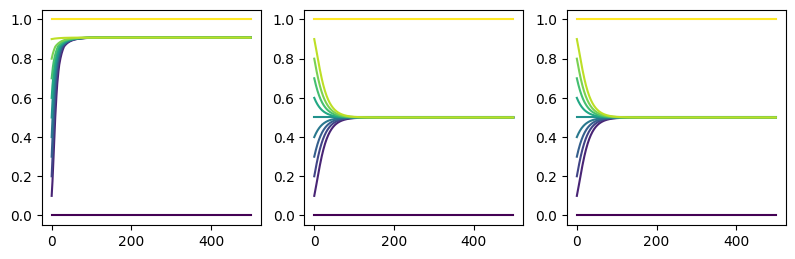

In [ ]:
trajectories_1D(qbSARSA, x, res, NrRandom=1)

In [ ]:
X = 0.5 * np.ones((1, 3, 2))

In [ ]:
mae.RPEisa(X)

Array([[[ 1.4931473 , -0.10685289],
        [ 0.6931472 ,  0.6931472 ],
        [ 0.6931472 ,  0.6931472 ]]], dtype=float32)

In [ ]:
Risar = qbSARSA.Risar(X)
Risa = np.einsum('ijkl,l->ijk', Risar, qbSARSA.gridpoints)
Risa

array([[[ 1.92193416e-01, -1.92193416e-01],
        [-5.14221602e-17, -5.14221602e-17],
        [-5.14221602e-17, -5.14221602e-17]]])

In [ ]:
mae.Risa(X)

Array([[[ 0.20000002, -0.20000002],
        [ 0.        ,  0.        ],
        [ 0.        ,  0.        ]]], dtype=float32)

In [ ]:
mae.Qisa(X)

Array([[[ 0.20000002, -0.20000002],
        [ 0.        ,  0.        ],
        [ 0.        ,  0.        ]]], dtype=float32)

In [ ]:
qbSARSA.Qisa(X)

Array([[[1.0921934 , 0.70780647],
        [0.70714283, 0.70714283],
        [0.70714283, 0.70714283]]], dtype=float32)

In [ ]:
mae.Vis(X)

Array([[0., 0., 0.]], dtype=float32)

In [ ]:
qbSARSA.Vis(X)

Array([[0.78571427, 1.        , 1.        ]], dtype=float32)

In [ ]:
mae.Tisas(X)

Array([[[[0. , 0.6, 0.4],
         [0. , 0.4, 0.6]],

        [[1. , 0. , 0. ],
         [1. , 0. , 0. ]],

        [[1. , 0. , 0. ],
         [1. , 0. , 0. ]]]], dtype=float32)

In [ ]:
qbSARSA.Tisas(X)

Array([[[[0. , 0.6, 0.4],
         [0. , 0.4, 0.6]],

        [[1. , 0. , 0. ],
         [1. , 0. , 0. ]],

        [[1. , 0. , 0. ],
         [1. , 0. , 0. ]]]], dtype=float32)